### The model matching problem
Given the plant $P$, we want to design a controller $K$ so that the closed-loop transfer function $T$ from the reference $r$ to the output $\tilde y$ (complementary sensitivity) closely matches a given closed loop $T_0$. This way, if the reference transfer function $T_0$ is designed so as to satisfy some performance requirements (for example, on the rise time $t_s$ and overshoot $\hat s$), achieving $T\approx T_0$ guarantees that the specifications are satisfied. This can be formaulated in an $H_\infty$ context as the minimization of the model matching error $||T-T_0||_\infty$. To formulate this as the standard problem, we need to define a suitable performance input $w$ and performance output $z_1$ so that $T-T_0$ is precisely the transfer function from $w$ to $z_1$. Choosing $w$ as the reference signal $r$, and being $T$ the transfer function from $r$ to $y_p$, we can define $z_1$ as the difference between $y_p$ and the output $y_0$ of $T_0$ with input $r$. For added flexibility, it is convenient to consider $||W_o(T-T_0)||_\infty$ as the performance metric, where $W_o$ is some stable filter. This way, a closer matching between $T$ and $T_0$ can be enforced at lower frequencies (within the bandwidth of $T$), where matching is more important in order to achieve the same $t_s$ and $\hat s$ as $T_0$, while leaving room for mismatch at higher frequencies to accommodate additional requirements, for example on the command sensitivity. Therefore, input $w$ is chosen as the reference signal $r$ and the performance output as $z_1=W_o(y_p-y_0)$. Computing as usual the transfer function from $[w\ u]$ to $[z_1\ y]$ yields the LFT for this problem:
$$
\begin{bmatrix}
z_1 \\
y
\end{bmatrix}
=
G
\begin{bmatrix}
w \\
u
\end{bmatrix}
\quad
G =
\begin{bmatrix}
- W_oT_0 & W_oP \\
I & -P
\end{bmatrix}
$$

We can also include as an additional performance requirement, the standard bound on the reference-to-command transfer function $KS$, we add a performance weight $W_u$ on the command signal $u$, obtaining a $z_2=W_u u$ performance signal and we take the latter into account in the performance outputs so that $
z =
\begin{bmatrix}
z_1 \\
z_2
\end{bmatrix}
$, with the corresponding $G$ matrix
$$
G =
\begin{bmatrix}
- W_oT_0 & W_oP \\
0 & W_u \\
I & -P
\end{bmatrix}
$$
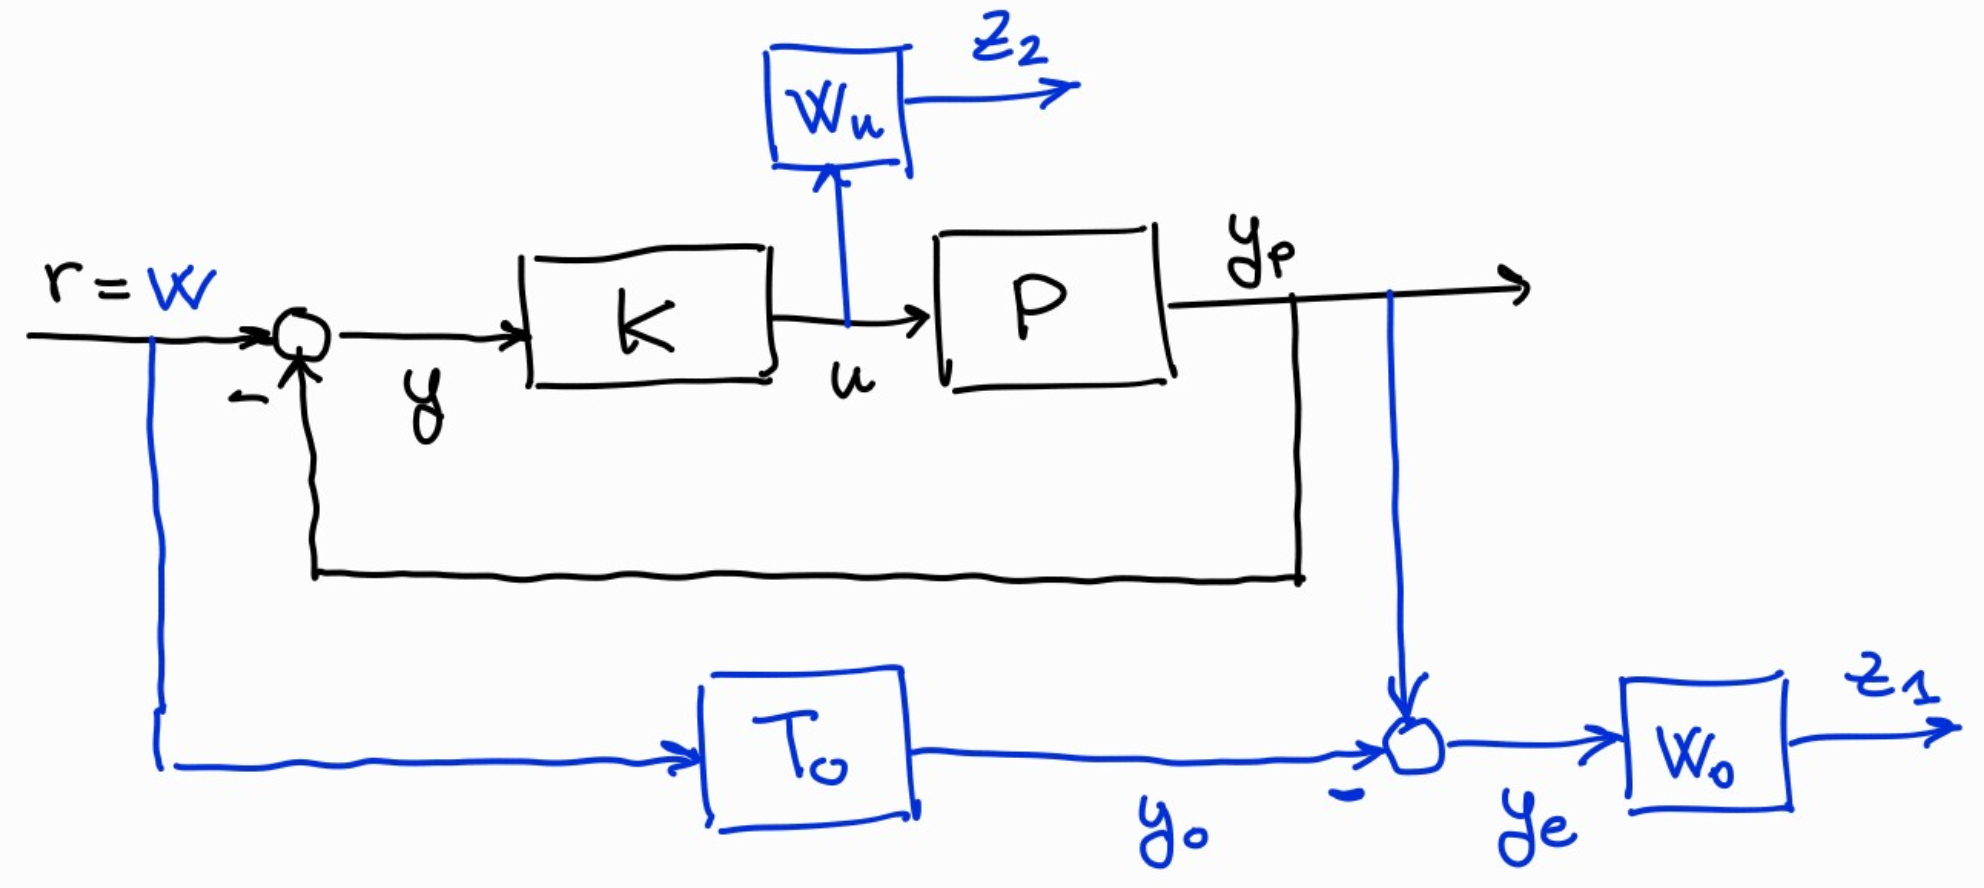

### The plant
---
Elastic robot joint model


\begin{cases}
J \ddot{\theta} + B (\dot{\theta} - \dot{q}) + K (\theta - q) = u   \quad Motor \\
M \ddot{q} + B (\dot{q} - \dot{\theta}) + K (q - \theta) = 0 \quad Payload
\end{cases}

Transfer function between the joint position and the commanded torque:
$$
P(s)=\frac{Q(s)}{U(s)}=\frac{B s + K}{s^2 \left( J M s^2 + (B J + B M) s + (J K + K M) \right)}
$$

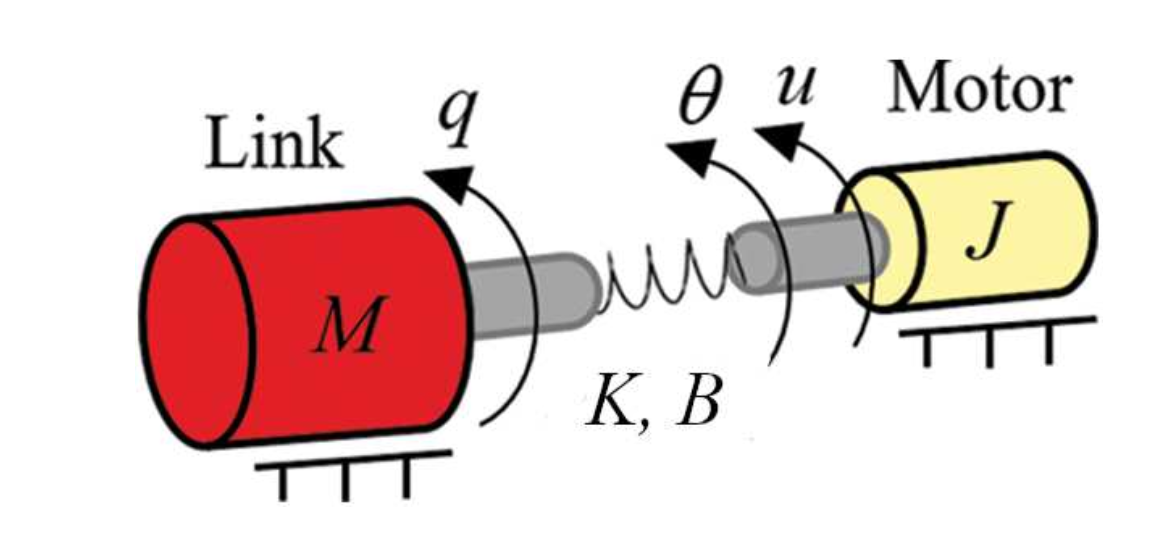

# Specifications
- Overshoot of the step response $\hat s$ below 10%;
- Rise time of the step response $t_s$ between 0.6s and 0.8s;\\
- Amplification on the command input of high-frequency noise $n_r$ on the reference signal less or equal to −20 dB when the noise frequency is $ω_{nr}\geq 60$ rad/s


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import control as ct
import slycot as sly
import cvxpy as cp
from itertools import product
import rpc_diism.robust as rb

s=ct.tf('s')

In [2]:
# Plant Parameters

J = 0.01
K = 7.3 
B = 0.04 
M = 0.009


In [3]:
#Frequency range
omega = np.logspace(-2, 4, 1000)

In [4]:
# Plant P
P = ct.tf([B, K],[J*M, B*M+B*J, K*M+K*J,0,0])
display("Plant tf P", P)

'Plant tf P'

TransferFunction(
array([0.04, 7.3 ]),
array([9.000e-05, 7.600e-04, 1.387e-01, 0.000e+00, 0.000e+00]),
outputs=1, inputs=1)

In [5]:
# Natural frequency of the dominant poles of the plant
wp = 27 
epsc = 1e-6

# We move the poles at zero slightly to the left to avoid numerical problems in the computation
# of the H-infinity controller. The algorithm behaves better if the plant is strictly proper and stable.
sc =s+wp*epsc
Pc = (K+B*sc)/(sc**4*(J*M)+sc**3*((M*B+B*J))+sc**2*(M*K+K*J))

display("Plant tf P corrected", Pc)


'Plant tf P corrected'

TransferFunction(
array([0.04      , 7.30000108]),
array([9.00000000e-05, 7.60009720e-04, 1.38700062e-01, 7.48980166e-06,
       1.01112315e-10]),
outputs=1, inputs=1)

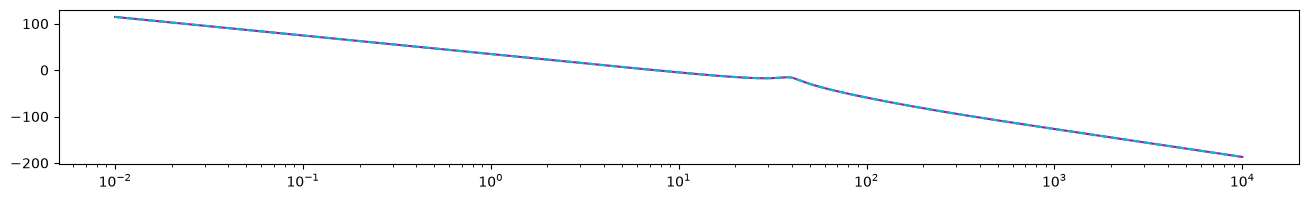

In [6]:
#Comparing the Bode plot we can see the almost perfect overlap between the original plant with that of the shifted one
m1, p1, _ = P.frequency_response(omega)
m2, p2, _ = Pc.frequency_response(omega)
plt.figure(figsize=(16, 2))
plt.semilogx(omega, 20*np.log10(m1), 'm', label=r'$\P$')
plt.semilogx(omega, 20*np.log10(m2), 'c--', label=r'$\Pc)$')

### Performance specifications
---
The ideal matching function is a second order system for which the natural frequency $\omega_n$ and the damping $\zeta$ must be chosen in such a way as to respect the overshoot $\hat{s}$ and rise time $t_s$, a damping of $\zeta$=0.6 and $\omega_n$ = 3.7 is chosen.

$$
T_0(s)=\frac{1}{1+\frac{2\zeta s}{\omega_n}+\frac{s^2}{\omega_n^2}}, \quad \omega_n=3,7, \quad \zeta=0.6
$$

In [7]:
# Matching function T_0 of 2° order
damping=0.6 
wn = 3.7 
T_0_num=[1]
T_0_den=[1/wn**2,(2*damping)/wn,1]
T_0= ct.tf(T_0_num,T_0_den)

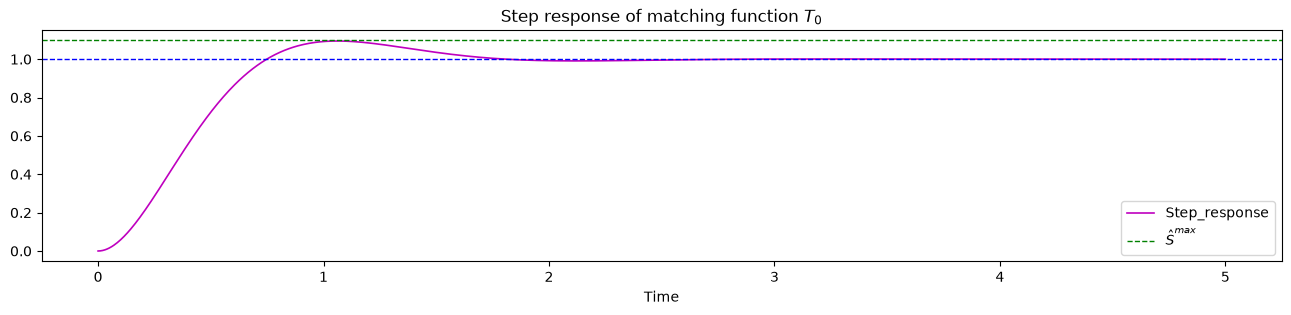

In [8]:
t, step_ = ct.step_response(T_0,np.linspace(0,5,1000))
plt.figure(figsize=(16, 3))
plt.plot(t, step_, label="Step_response", linewidth=1.2,color='m')
plt.axhline(y=1, color='b', linestyle='--', linewidth=1, label="")   
plt.axhline(y=1.1, color='g', linestyle='--', linewidth=1, label=r"$\hat{S}^{max}$") 

plt.xlabel("Time")
plt.title(r'Step response of matching function $T_0$')

plt.legend()
plt.show()

 Since we want to match the transient of the closed loop response $T$ with that of $T_0$, it is necessary that the difference between the two is very low in the frequency range corresponding to the bandwith $B_3$ of the desired closed-loop system. The weight that is suitable to achieve this goal is of the same shape as the weight $W_e$ that usually weighs the sensitivity function $S$. The choice of parameters must ensure that at low frequencies the weight is very high forcing the closed loop to closely follow the desired behavior. At high frequencies, the weight should allow some flexibility, in fact matching is less critical, while the specification on $KS$ is. As a tentative, we can design a filter $W_o$ such that the gain of its inverse is below -30 dB at frequencies below $B_3$.

On the other hand, the weight on $W_u$ must constrain $KS$ to stay below the maximum allowed amplification in the required band (cyan region in the next figure).

In [9]:
# Weight on matching error
# Compute the desired closed-loop bandwidth
B3 = 3/0.6
Mo = 10
wbo = 35*B3
epso = 1e-3
Wo = ct.ss(rb.weightS(wbo,Mo,epso,1))
Wo_inv = rb.invss(Wo)


In [10]:
# Weight on KS (command sensitivity)
M_u = 1000
eps = 0.001
wbc = 9.5*wn
Wu = 4*ct.ss(rb.weightU(wbc, M_u,eps,2))
Wu_inv = rb.invss(Wu)


In [11]:
# Singular values of weights
Wu_inv_sv = rb.sigma(Wu_inv, omega)
Wo_inv_sv = rb.sigma(Wo_inv, omega)

Text(0.5, 1.0, 'Singular values of $W_o^{-1}$')

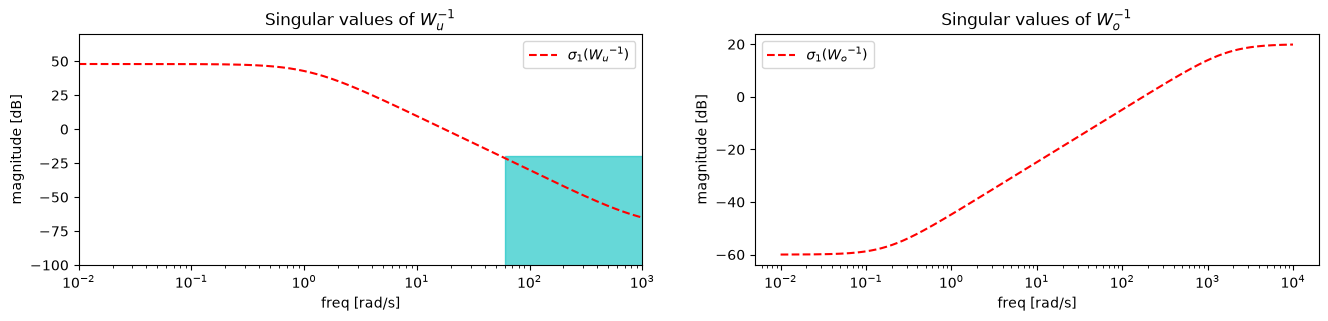

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3))

axes[0].semilogx(omega, 20*np.log10(Wu_inv_sv), 'r--', label=r'$\sigma_1({W_u}^{-1})$')
axes[0].set_ylim([-100,70])
axes[0].set_xlim([1e-2,1e3])
axes[0].set_ylabel('magnitude [dB]')
axes[0].set_xlabel('freq [rad/s]')
axes[0].fill_between(omega, -20, -120, where=(omega > 60), color='c', alpha=0.6)
axes[0].legend()
axes[0].set_title(r'Singular values of $W_u^{-1}$')

axes[1].semilogx(omega, 20*np.log10(Wo_inv_sv), 'r--', label=r'$\sigma_1({W_o}^{-1})$')
axes[1].set_ylabel('magnitude [dB]')
axes[1].set_xlabel('freq [rad/s]')
axes[1].legend()
axes[1].set_title(r'Singular values of $W_o^{-1}$')

Computation of the LFT for the H-infinity problem

In [13]:
#Matching function block
T_0.input_labels = ['w']
T_0.output_labels = ['y0']
#Correct plant block
fbk = ct.summing_junction(inputs=['w','-yp'], outputs=['y'])
#Matching weight block
Wu.input_labels = ['u']
Wu.output_labels = ['z2']
#Command input block
Pc.input_labels = ['u']
Pc.output_labels = ['yp']
#Difference matching
sum = ct.summing_junction(inputs=['yp','-y0'], outputs=['ye'])
# Weight matching
Wo.input_labels = ['ye']
Wo.output_labels = ['z1']
#G block
G = ct.minreal(ct.interconnect([T_0,Pc, Wo, Wu, fbk,sum],inputs=['w','u'],outputs=['z1','z2','y']))

0 states have been removed from the model


Compute the $H_\infty$ controller

In [14]:
K_c, Tzw, gamma, rcond = rb.hinfsyn(G, nmeas=1, ncon=1)
display("gamma:", gamma)

'gamma:'

0.9605914144117378

Observe that the optimal $\gamma$ is slightly below 1. This means that the frequency response profiles of $KS$ and $T-T_0$ will actually lie below the profiles of $W_u$ and $W_o$, respectively.

### Evaluation of performance

Text(0.5, 1.0, 'Singular values of KS vs.  $\\gamma \\sigma({Wu}^{-1})$')

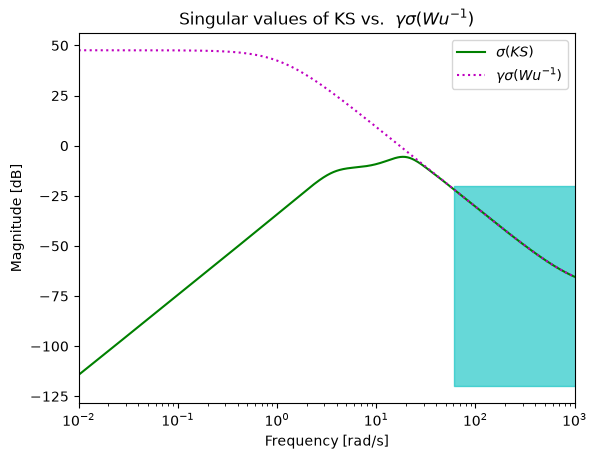

In [15]:
# KS vs gamma*sigma1(Wu^-1)
S = ct.feedback(1, P * K_c)
KS_sv = rb.sigma(K_c * S, omega)

Wuinv_sv = rb.sigma(Wu_inv, omega) * gamma
plt.semilogx(omega, 20 * np.log10(KS_sv), 'g', label=r'$\sigma(KS)$')
plt.semilogx(omega, 20 * np.log10(Wuinv_sv), 'm:', label=r'$\gamma \sigma({Wu}^{-1})$')
plt.fill_between(omega, -20, -120, where=(omega > 60), color='c', alpha=0.6)
plt.xlim([1e-2,1e3])
plt.ylabel('Magnitude [dB]')
plt.xlabel('Frequency [rad/s]')
plt.legend()
plt.title(r'Singular values of KS vs.  $\gamma \sigma({Wu}^{-1})$')


Text(0.5, 1.0, 'Singular values of (T-$T_0$) vs.  $\\gamma \\sigma({Wo}^{-1})$')

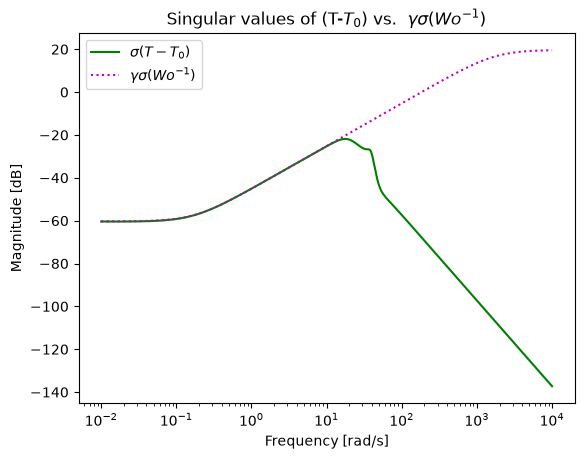

In [16]:

# T-T0 vs gamma*sigma1(Wo^-1)
T = ct.feedback(P * K_c)
matching = T-T_0
match_sv = rb.sigma(matching, omega)

Woinv_sv = rb.sigma(Wo_inv, omega) * gamma
plt.semilogx(omega, 20 * np.log10(match_sv), 'g', label=r'$\sigma(T-T_0)$')
plt.semilogx(omega, 20 * np.log10(Woinv_sv), 'm:', label=r'$\gamma \sigma({Wo}^{-1})$')
plt.ylabel('Magnitude [dB]')
plt.xlabel('Frequency [rad/s]')
plt.legend()
plt.title(r'Singular values of (T-$T_0$) vs.  $\gamma \sigma({Wo}^{-1})$')


Text(0.5, 1.0, 'Frequency Response of T and $T_0$')

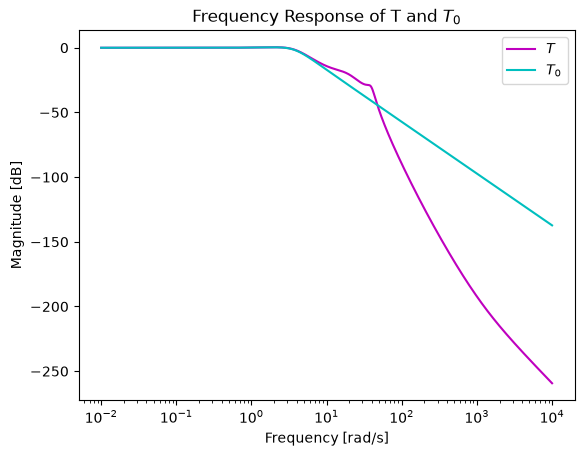

In [17]:

# Frequency response comparison between T and T0
m1, p1, _ = T.frequency_response(omega)
m2, p2, _ = T_0.frequency_response(omega)

plt.semilogx(omega, 20 * np.log10(m1), 'm', label=r'$T$')
plt.semilogx(omega, 20 * np.log10(m2), 'c', label=r'$T_0$')
plt.ylabel('Magnitude [dB]')
plt.xlabel('Frequency [rad/s]')
plt.legend()
plt.title(r'Frequency Response of T and $T_0$')


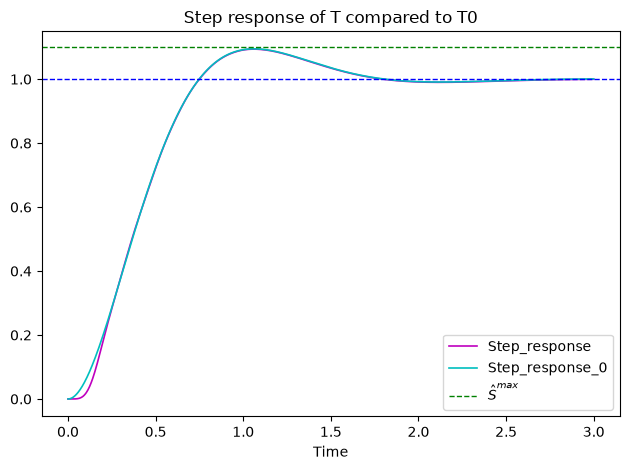

In [18]:
# Step response of T compared to T0
t, step_ = ct.step_response(T, np.linspace(0, 3, 1000))
t, step0_ = ct.step_response(T_0,np.linspace(0,3,1000))
plt.plot(t, step_, label="Step_response", linewidth=1.2, color='m')
plt.plot(t, step0_, label="Step_response_0", linewidth=1.2, color='c')
plt.axhline(y=1, color='b', linestyle='--', linewidth=1, label="")   
plt.axhline(y=1.1, color='g', linestyle='--', linewidth=1, label=r"$\hat{S}^{max}$") 
plt.xlabel("Time")
plt.title(r'Step response of T compared to T0')
plt.legend()

plt.tight_layout()
plt.show()